# Evaluación del modelo

**Fase:** E8

## Objetivo

Medir el rendimiento y la calibración del modelo en el conjunto de test aislado.

## Relación con la pregunta de investigación

> ¿Puede un agente con RAG explicar el diagnóstico de un vehículo a partir de datos OBD-II, rastreando cada explicación hasta su evidencia de origen, y reconocer cuándo la evidencia disponible no es suficiente para sostener una explicación en lugar de generar una hipótesis sin fundamento?

La confianza del modelo entra en el criterio de suficiencia: solo es utilizable si está calibrada.

## Hipótesis

_Por declarar antes de ejecutar la fase._

## Datos

_Dataset, versión y partición utilizados._

## Método

_Procedimiento, parámetros y semillas._

## Métricas

_Qué se mide y con qué instrumento._

## Criterio de éxito o refutación

_Fijado antes de mirar los resultados._


In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
# `tables/` y `figures/` están fuera del control de versiones: un clon no los
# trae. `artifacts/` es su copia versionada y es la que el tribunal tiene.
ARTEFACTOS_TABLAS = RAIZ / 'artifacts' / 'tables'
ARTEFACTOS_FIGURAS = RAIZ / 'artifacts' / 'figures'

import pandas as pd

from mecanico_ia_exp.config import paths


## Rendimiento por clase y calibración

In [2]:
import json
b = json.loads((paths.EXPERIMENTS / 'E6_baseline_synthetic_v2.json').read_text())
pd.DataFrame(b['metrics']['per_class'])

,label,precision,recall,f1,support,pr_auc
0,F00_normal,0.7,1.0000,0.8235,28,0.7781
1,F01_vacuum_leak,1.0,1.0000,1.0000,14,1.0000
2,F02_maf_drift,1.0,1.0000,1.0000,14,1.0000
3,F03_thermostat_stuck,1.0,0.6429,0.7826,14,0.8324
4,F04_o2_lag,1.0,1.0000,1.0000,14,1.0000
5,F05_misfire,1.0,0.5000,0.6667,14,0.8335


In [3]:
print('calibración sin corregir:', b['metrics']['calibration'])
print()
print('El bosque está INFRAconfiado: acierta más de lo que dice.')
print('Un umbral sobre esta confianza se abstendría de más.')

calibración sin corregir: {'ece': 0.1439, 'mean_confidence': 0.738, 'accuracy': 0.8776, 'overconfidence': -0.1395}

El bosque está INFRAconfiado: acierta más de lo que dice.
Un umbral sobre esta confianza se abstendría de más.


### Dónde falla: el límite físico del termostato

Las ventanas que el modelo falla tienen el motor por debajo del techo que el fallo impone. Ahí la señal de un motor averiado es **idéntica** a la de uno sano.

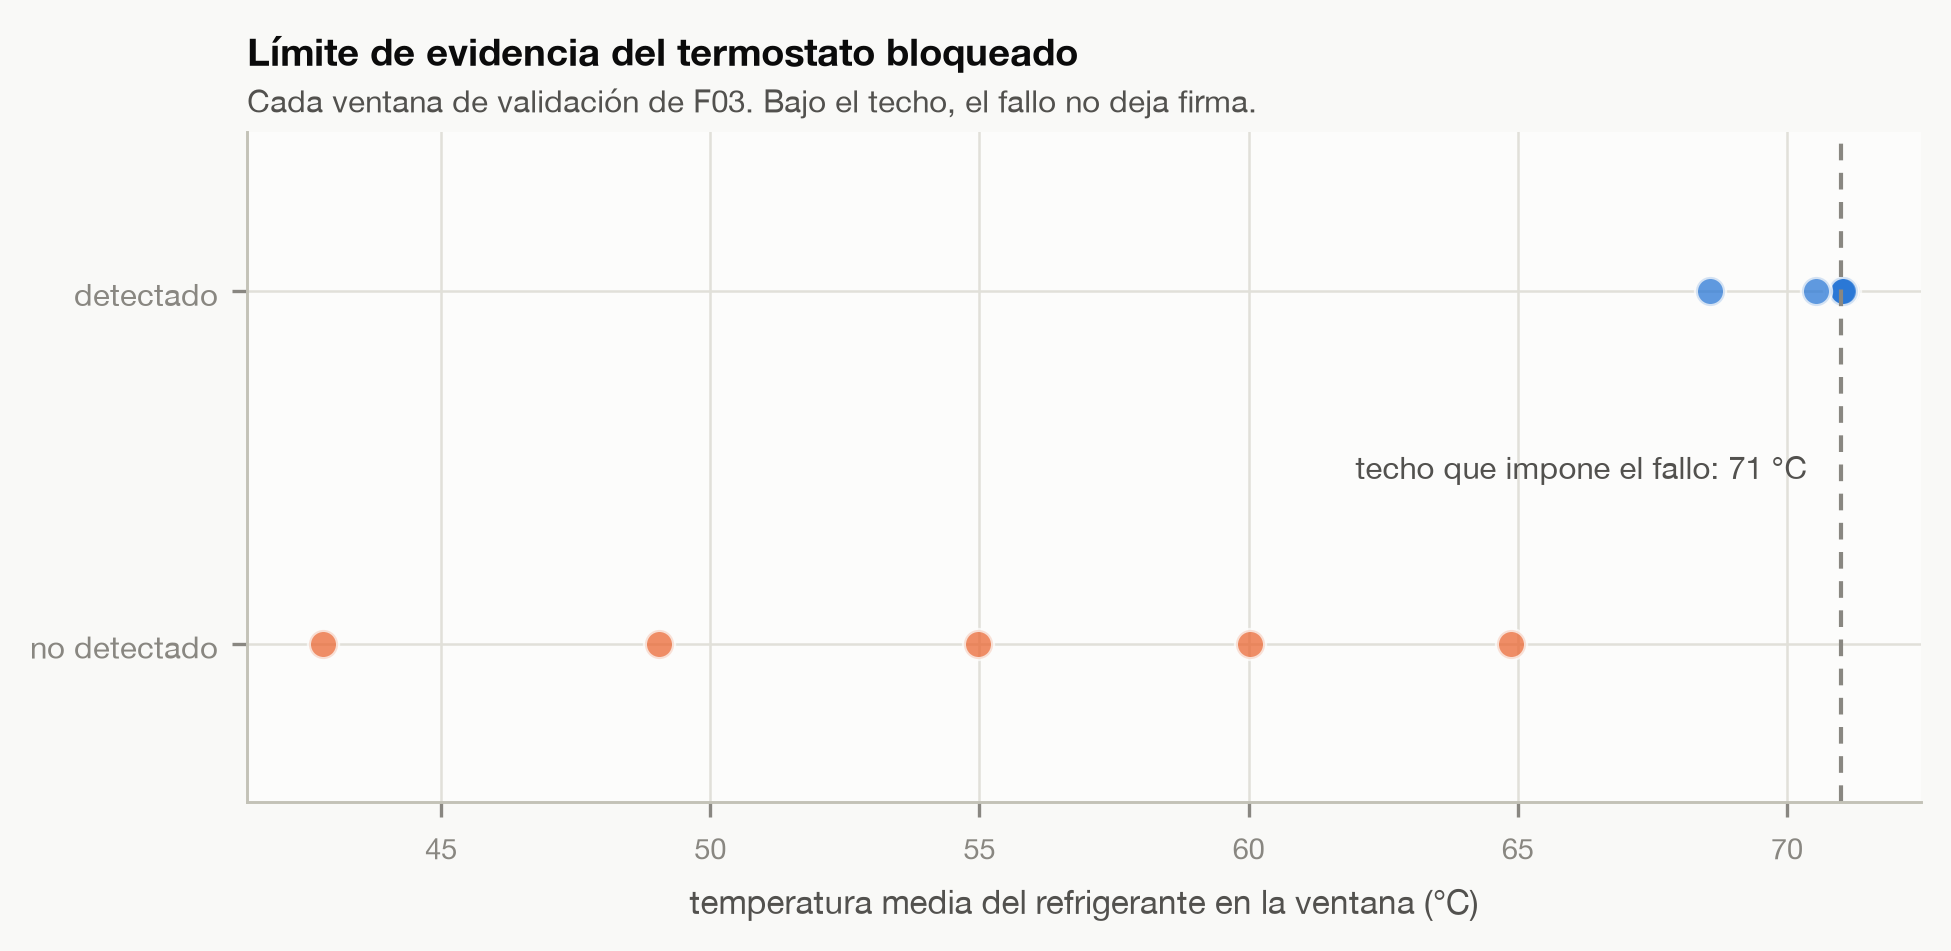

In [4]:
from IPython.display import Image
Image(str(ARTEFACTOS_FIGURAS / 'FIG-E6-02_limite_evidencia_f03.png'))

## Resultados

_Lo observado, sin interpretación._

## Interpretación

_Qué significa, y qué no significa._

## Limitaciones

_Qué queda fuera del alcance de lo mostrado._

## Conclusión experimental

_Respuesta al criterio fijado en la cabecera._

## Artefactos generados

_Ficheros producidos, con su ruta._
